# From one tree to an ensemble

After this block you can explain how a decision tree chooses its splits, why a deep tree overfits and how pruning controls it, and how random forests and gradient boosting combine many trees into one prediction. You will fit and draw a tree on the Telco churn data and compare it with a random forest and a gradient boosting model on the same cross-validation folds. This serves the first learning outcome of Session 10: *explain how decision trees, random forests and gradient boosting predict*.

## Teaching map

| Section | Minutes | What it delivers |
|---|---|---|
| 1 · Decision trees: splits and Gini impurity | 11 | Gini impurity by hand on ten customers, the first tree on the churn data |
| 2 · Tree depth, overfitting and pruning | 11 | Training versus cross-validated score, depth chosen by CV, cost-complexity pruning |
| 3 · Bagging and random forests | 9 | Bootstrap samples, averaging many trees, the out-of-bag score |
| 4 · Gradient boosting | 8 | Boosting by hand on residuals, scikit-learn's boosting classifiers |
| Worked example | 6 | Tree, forest and boosting on the same churn folds |
| **Total** | **45** | |

**Core path for the lecture:** the unnumbered part of each section (`## 1` to `## 4`) and the worked example. The numbered subsections marked *(depth: self-study or if time allows)* go deeper and can be skipped in class: 1a decision boundaries on the penguins data, 1b the arrays inside a fitted tree, 2a shallow versus deep trees and regression trees, 2b the whole pruning path, 3a bagging step by step, 3b `max_features` and decorrelation, 4a residuals drawn, 4b histogram binning.

```mermaid
flowchart LR
    g["Gini: how mixed<br/>is a node?"] --> t["One tree:<br/>greedy splits"]
    t --> d{"Deep tree<br/>overfits"}
    d -->|"limit or prune"| p["Pruned tree"]
    d -->|"average many deep trees"| rf["Bagging,<br/>random forest"]
    d -->|"add many small trees"| gb["Gradient<br/>boosting"]
    p --> cmp["Compare on<br/>the same folds"]
    rf --> cmp
    gb --> cmp
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we import the tools used in every section: NumPy, pandas and matplotlib for figures. `OMP_NUM_THREADS = "1"` runs scikit-learn's histogram boosting on one CPU thread: on laptops with many cores, its default of one thread per core can make small fits much slower, not faster.

In [2]:
os.environ["OMP_NUM_THREADS"] = "1"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## 1 · Decision trees: splits and Gini impurity

A **decision tree** predicts by asking a short sequence of yes/no questions about a row, like the script a call-centre agent follows: "Is the contract monthly?", then "Has the customer been with us less than a year?". Each question is a **split**. The rows that answer "yes" go to one **child node**, the others to the second. A node that is not split any further is a **leaf**, and it predicts the majority class of the training rows that ended up there (or their class shares, as a probability).

To choose a question, the tree needs a number that says how mixed a node is. The **Gini impurity** is that number:

G = 1 − (p₁² + p₂² + … + p_K²), where p_k is the share of class k in the node.

In words: G is the chance that two rows drawn at random from the node belong to different classes. A pure node has G = 0. A node with two classes in equal shares has G = 1 − (0.5² + 0.5²) = 0.5, the worst case for two classes.

A split is judged by the **weighted impurity** of its two children: each child's G, weighted by its share of the rows. The tree tries every feature and every threshold and keeps the split with the lowest weighted impurity. It does this **greedily**: the best split now, without looking ahead.

**Worked example.** Ten customers, four of whom churned:

| Contract | month | month | month | month | month | month | year | year | year | year |
|---|---|---|---|---|---|---|---|---|---|---|
| Tenure (months) | 1 | 2 | 3 | 5 | 20 | 30 | 8 | 25 | 40 | 60 |
| Churn | 1 | 1 | 1 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |

- Parent node: 4 of 10 churn, G = 1 − (0.4² + 0.6²) = **0.48**.
- Split "contract = month": six monthly customers with 4 churners, G = 1 − ((4/6)² + (2/6)²) = 0.444; four yearly customers, all stayed, G = 0. Weighted: 0.6 · 0.444 + 0.4 · 0 = **0.267**.

Next we type the ten customers into a DataFrame, so that Python can check the arithmetic.

In [3]:
toy = pd.DataFrame({
    "contract": ["month"] * 6 + ["year"] * 4,
    "tenure": [1, 2, 3, 5, 20, 30, 8, 25, 40, 60],
    "churn": [1, 1, 1, 0, 1, 0, 0, 0, 0, 0],
})
toy.T

,0,1,2,3,4,5,6,7,8,9
contract,month,month,month,month,month,month,year,year,year,year
tenure,1,2,3,5,20,30,8,25,40,60
churn,1,1,1,0,1,0,0,0,0,0


Two small functions do the work. `np.bincount(y, minlength=2)` counts the 0s and 1s, so dividing by the number of rows gives the class shares. `split_gini` takes a Boolean `mask` (True = left child) and returns the weighted impurity; `mask.mean()` is the share of rows in the left child.

In [4]:
def gini(y):
    """Gini impurity: 0 for a pure node, 0.5 for a 50/50 node with two classes."""
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - (p ** 2).sum()


def split_gini(mask, y):
    """Weighted Gini impurity of the two children defined by a Boolean mask."""
    return mask.mean() * gini(y[mask]) + (~mask).mean() * gini(y[~mask])

**Predict before running.** Is "tenure < 4" a better first split than "contract = month"? The next cell prints the parent impurity, the contract split and four tenure thresholds.

In [5]:
y_toy = toy["churn"].to_numpy()
print("parent:", round(gini(y_toy), 3))
print("contract = month:", round(split_gini(toy["contract"].eq("month").to_numpy(), y_toy), 3))
for t in [2.5, 4, 12.5, 25]:
    print(f"tenure < {t}:", round(split_gini(toy["tenure"].lt(t).to_numpy(), y_toy), 3))

parent: 0.48
contract = month: 0.267
tenure < 2.5: 0.3
tenure < 4: 0.171
tenure < 12.5: 0.4
tenure < 25: 0.267


"tenure < 4" wins: the three shortest-tenure customers form a pure child, and the other seven contain only one churner. Now let scikit-learn search. `DecisionTreeClassifier(max_depth=1)` grows a tree with a single split (a **stump**); `export_text` prints its rules, and `tree_.impurity` holds the impurity of each node.

In [6]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

stump = DecisionTreeClassifier(max_depth=1).fit(toy[["tenure"]], toy["churn"])
print(export_text(stump, feature_names=["tenure"]))
print(stump.tree_.impurity.round(3))  # root, left child, right child

|--- tenure <= 4.00
|   |--- class: 1
|--- tenure >  4.00
|   |--- class: 0

[0.48  0.    0.245]


scikit-learn picks the same split. It writes the threshold as the midpoint between the neighbouring values 3 and 5 (≤ 4.0). Only the *order* of the values matters to a tree, so trees need no feature scaling.

> **Note.** Gini impurity is not the Gini coefficient of income inequality, nor the "Gini" of credit scoring (2 · AUC − 1). `criterion="entropy"` is an alternative impurity measure that usually picks very similar splits.

Now the real data: the IBM Telco churn table of Session 8 (7,043 customers). Next we read it from GitHub, turn `TotalCharges` into numbers (11 blanks become 0), and one-hot encode the text columns with `pd.get_dummies`, because scikit-learn trees need numeric input. `train_test_split(..., stratify=y)` keeps the churn rate equal in both parts.

In [7]:
from sklearn.model_selection import train_test_split

URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
       "master/data/Telco-Customer-Churn.csv")
df = pd.read_csv(URL)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["customerID", "Churn"])
cat = X.select_dtypes(exclude="number").columns.tolist()
X_oh = pd.get_dummies(X, columns=cat, drop_first=True, dtype=int)
X_tr, X_te, y_tr, y_te = train_test_split(X_oh, y, test_size=0.25, stratify=y, random_state=0)
print(X_oh.shape, "churn rate", round(y.mean(), 3))

(7043, 30) churn rate 0.265


A tree of depth 2 asks at most two questions. `show_weights=True` prints the number of stayers and churners in each leaf.

In [8]:
small = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_tr, y_tr)
print(export_text(small, feature_names=list(X_oh.columns), show_weights=True))

|--- tenure <= 16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- weights: [794.00, 321.00] class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- weights: [256.00, 551.00] class: 1
|--- tenure >  16.50
|   |--- InternetService_Fiber optic <= 0.50
|   |   |--- weights: [1768.00, 114.00] class: 0
|   |--- InternetService_Fiber optic >  0.50
|   |   |--- weights: [1062.00, 416.00] class: 0



`plot_tree` draws the same tree. `filled=True` colours each node by its majority class; the darker the colour, the purer the node.

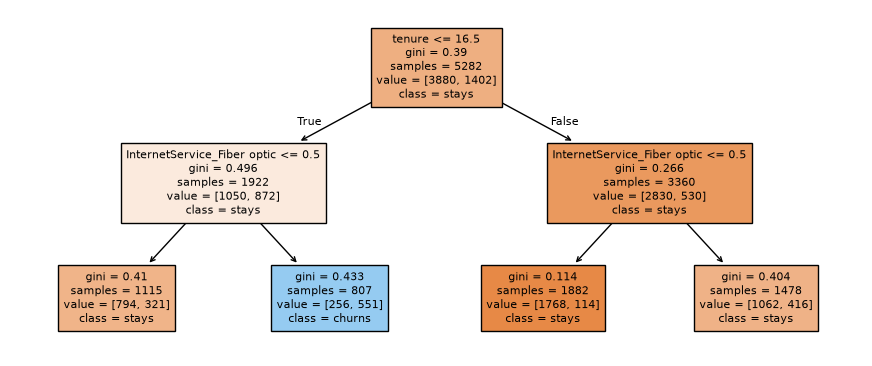

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
plot_tree(small, feature_names=list(X_oh.columns), class_names=["stays", "churns"],
          filled=True, impurity=True, fontsize=8, ax=ax)
plt.show()

Each path from the root to a leaf is an if-then rule. New customers (tenure ≤ 16.5 months) with fibre-optic internet form the only leaf where churners are the majority; the tree predicts "churns" for them and "stays" for everyone else. That readability is why shallow trees are used to describe customer segments, even when another model makes the predictions.

> **Note.** The first split is not "the most important cause" of churn. Correlated features (tenure and total charges) can stand in for each other, and a small change in the data can change the first split. A single tree describes the training data; it is not a causal model.

### 1a · How a tree carves up the feature space (depth: self-study or if time allows)

*Adapted from [Build a classification decision tree](extras/01-trees-classification.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

With two features we can draw what a model does. The penguins data (Horst, Hill & Gorman, 2020) has two measurements of the bill (culmen length and depth) and three species. A linear classifier separates the classes with oblique lines, combinations of both features. A tree splits on **one feature at a time**, so its boundaries are always parallel to an axis.

Next we read the penguins table from the session's `datasets/` folder and split it. Paths start at the repository root (first code cell).

In [10]:
penguins = pd.read_csv("sessions/10-tree-based-models/datasets/penguins_classification.csv")
culmen_columns = ["Culmen Length (mm)", "Culmen Depth (mm)"]
target_column = "Species"
data, target = penguins[culmen_columns], penguins[target_column]
data_train, data_test, target_train, target_test = train_test_split(data, target, random_state=0)
target.value_counts()

Species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

`DecisionBoundaryDisplay.from_estimator` colours every point of the plane by the class the model would predict there. We write a small helper that draws the boundary of any fitted model and the penguins on top, then use it for a logistic regression.

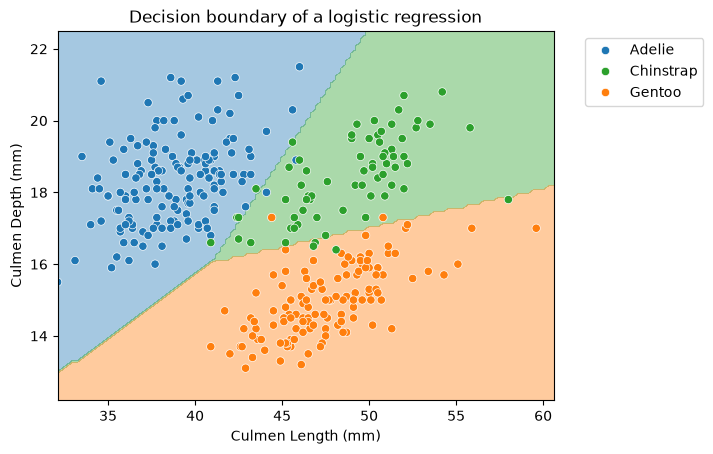

test accuracy 0.98


In [11]:
import seaborn as sns
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression

SPECIES, COLOURS = ["Adelie", "Chinstrap", "Gentoo"], ["tab:blue", "tab:green", "tab:orange"]


def plot_boundary(model, title):
    DecisionBoundaryDisplay.from_estimator(model, data_train, response_method="predict", alpha=0.4,
                                           multiclass_colors=COLOURS)
    sns.scatterplot(data=penguins, x=culmen_columns[0], y=culmen_columns[1], hue=target_column,
                    hue_order=SPECIES, palette=COLOURS)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.title(title)
    plt.show()


linear_model = LogisticRegression().fit(data_train, target_train)
plot_boundary(linear_model, "Decision boundary of a logistic regression")
print("test accuracy", round(linear_model.score(data_test, target_test), 2))

The lines are not perpendicular to an axis: each one combines both features through the model's weights. A tree's decision rule is made of three things instead: the feature used at each split, the threshold at each split, and the value predicted in each leaf. The number of splits grows with the data and the hyperparameters, which is why trees are called **non-parametric** models.

Next we fit a tree that may only make one split (`max_depth=1`) and draw its boundary and its structure.

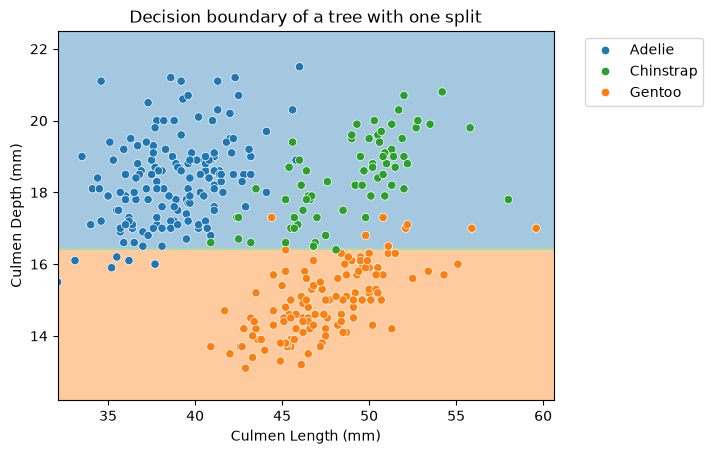

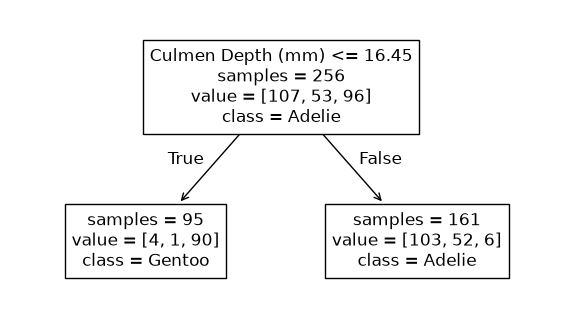

In [12]:
tree_peng = DecisionTreeClassifier(max_depth=1).fit(data_train, target_train)
plot_boundary(tree_peng, "Decision boundary of a tree with one split")
fig, ax = plt.subplots(figsize=(7, 4))
plot_tree(tree_peng, feature_names=culmen_columns, class_names=tree_peng.classes_.tolist(), impurity=False, ax=ax)
plt.show()

The single split uses culmen depth only; culmen length is ignored. A leaf predicts its most frequent class, and `predict_proba` returns the class shares of the training penguins in that leaf. `tree_.value` stores these shares per node; `apply` returns the leaf a row lands in. **Predict before running:** what happens to the probabilities if the culmen length is an absurd 10,000 mm?

In [13]:
new = pd.DataFrame({"Culmen Length (mm)": [0, 0, 10_000], "Culmen Depth (mm)": [15, 17, 17]})
print(tree_peng.predict(new))
print(pd.DataFrame(tree_peng.predict_proba(new), columns=tree_peng.classes_).round(3))
leaf = tree_peng.apply(new.iloc[[1]])[0]
print("class shares stored in that leaf:", tree_peng.tree_.value[leaf].round(3))
print("test accuracy of the stump:", round(tree_peng.score(data_test, target_test), 2))

['Gentoo' 'Adelie' 'Adelie']
   Adelie  Chinstrap  Gentoo
0   0.042      0.011   0.947
1   0.640      0.323   0.037
2   0.640      0.323   0.037
class shares stored in that leaf: [[0.64  0.323 0.037]]
test accuracy of the stump: 0.78


The probabilities for 10,000 mm are the same as for 0 mm, because the tree never looks at culmen length. One split cannot separate three species, so the stump underfits; Section 2 lets the tree grow.

### 1b · Inside a fitted tree (depth: self-study or if time allows)

*Adapted from [Understanding the decision tree structure](extras/03-tree-structure.ipynb) (scikit-learn developers, BSD-3-Clause).*

A fitted scikit-learn tree keeps its whole structure in parallel arrays under `tree_`. Element `i` of each array describes node `i`; node 0 is the root.

- `children_left[i]`, `children_right[i]`: ids of the children, or −1 for a leaf;
- `feature[i]`, `threshold[i]`: the split rule (only meaningful for split nodes);
- `n_node_samples[i]`, `impurity[i]`: the number of training rows and the impurity of the node;
- `value[i]`: the class shares of the training rows in the node.

Next we walk through the depth-2 churn tree with a stack, the way the scikit-learn example does, and print each node with its depth.

In [14]:
t = small.tree_
stack, depth_of = [(0, 0)], {}
while stack:
    node, d = stack.pop()
    depth_of[node] = d
    if t.children_left[node] != t.children_right[node]:          # a split node
        stack += [(t.children_right[node], d + 1), (t.children_left[node], d + 1)]
for node in sorted(depth_of, key=lambda n: (depth_of[n], n)):
    pad = "    " * depth_of[node]
    if t.children_left[node] == -1:
        print(f"{pad}node {node}: leaf, {t.n_node_samples[node]} customers, churn share {t.value[node][0][1]:.2f}")
    else:
        print(f"{pad}node {node}: if {X_oh.columns[t.feature[node]]} <= {t.threshold[node]:.2f} "
              f"go to {t.children_left[node]}, else {t.children_right[node]}")

node 0: if tenure <= 16.50 go to 1, else 4
    node 1: if InternetService_Fiber optic <= 0.50 go to 2, else 3
    node 4: if InternetService_Fiber optic <= 0.50 go to 5, else 6
        node 2: leaf, 1115 customers, churn share 0.29
        node 3: leaf, 807 customers, churn share 0.68
        node 5: leaf, 1882 customers, churn share 0.06
        node 6: leaf, 1478 customers, churn share 0.28


`decision_path(X)` returns a sparse indicator matrix: entry (i, j) is 1 if row i passes through node j. Together with `apply`, it gives the rules used for one prediction. Next we print them for the first test customer.

In [15]:
customer = X_te.iloc[[0]]
nodes = small.decision_path(customer).indices
for node in nodes:
    if node == small.apply(customer)[0]:
        print(f"leaf {node}: predicted churn probability {small.predict_proba(customer)[0, 1]:.2f}")
        continue
    name, value = X_oh.columns[t.feature[node]], customer.iloc[0, t.feature[node]]
    sign = "<=" if value <= t.threshold[node] else ">"
    print(f"node {node}: {name} = {value} {sign} {t.threshold[node]:.2f}")

node 0: tenure = 11 <= 16.50
node 1: InternetService_Fiber optic = 0 <= 0.50
leaf 2: predicted churn probability 0.29


> 📖 **Read more:** [extras/01-trees-classification.ipynb](extras/01-trees-classification.ipynb) (INRIA scikit-learn MOOC) and [extras/03-tree-structure.ipynb](extras/03-tree-structure.ipynb) (scikit-learn gallery): the originals of the two depth sections above, including the decision path shared by a group of samples.

## 2 · Tree depth, overfitting and pruning

Without limits, a tree keeps splitting until every leaf is pure. In the end it can isolate single customers, so it fits the training data almost perfectly, noise included. That is **overfitting**: like a student who memorises last year's exam answers, it looks perfect on old questions and fails on new ones. A very shallow tree has the opposite problem: it can express only coarse rules (**underfitting**).

So **depth is a hyperparameter**, chosen by cross-validation on the training data (Session 7). Two ways to control the size of a tree:

- **Pre-pruning**: stop growing early with `max_depth`, `min_samples_leaf` (minimum rows per leaf) or `max_leaf_nodes`.
- **Post-pruning**: grow the full tree, then cut back branches that add little. scikit-learn's **cost-complexity pruning** charges a price `ccp_alpha` for every leaf: it keeps the subtree for which "total leaf impurity + α × number of leaves" is smallest. α = 0 keeps the full tree; a larger α gives a smaller tree.

**Predict before running.** The next cell scores trees of depth 1 to 15 and an unlimited tree with 5-fold cross-validation. What will the training accuracy of the unlimited tree be, roughly? And its cross-validated accuracy? `cross_validate(..., return_train_score=True)` returns both.

In [16]:
from sklearn.model_selection import cross_validate

rows = []
for depth in [*range(1, 16), None]:
    res = cross_validate(DecisionTreeClassifier(max_depth=depth, random_state=0), X_tr, y_tr,
                         cv=5, return_train_score=True)
    rows.append({"depth": depth or "none", "train": res["train_score"].mean(), "cv": res["test_score"].mean()})
curve = pd.DataFrame(rows).set_index("depth")
curve.round(3).T

depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,none
train,0.735,0.789,0.791,0.796,0.805,0.817,0.830,0.845,0.864,0.882,0.902,0.921,0.938,0.953,0.965,0.998
cv,0.735,0.787,0.793,0.786,0.794,0.787,0.785,0.777,0.775,0.761,0.758,0.743,0.743,0.736,0.733,0.727


A plot makes the pattern clear: the training score keeps rising with depth, the cross-validated score peaks early and then falls.

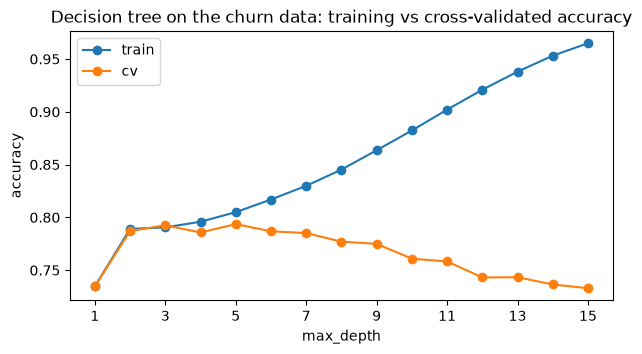

In [17]:
ax = curve.iloc[:-1].plot(marker="o", figsize=(7, 3.5))
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_title("Decision tree on the churn data: training vs cross-validated accuracy")
plt.show()

The training score of a deep tree says nothing about new customers. Next we let `GridSearchCV` choose two pre-pruning limits together, scored by ROC AUC (Session 8), on the training data only.

In [18]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(DecisionTreeClassifier(random_state=0),
                      {"max_depth": range(2, 12), "min_samples_leaf": [1, 10, 50]},
                      cv=5, scoring="roc_auc").fit(X_tr, y_tr)
print(search.best_params_, "CV ROC AUC", round(search.best_score_, 3))

{'max_depth': 5, 'min_samples_leaf': 50} CV ROC AUC 0.828


Post-pruning works from the other end. `cost_complexity_pruning_path` lists the α values at which branches disappear. We try a few of them and report the number of leaves and the cross-validated ROC AUC. `cross_val_score` returns one score per fold.

In [19]:
from sklearn.model_selection import cross_val_score

path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_tr, y_tr)
print(len(path.ccp_alphas), "candidate alphas")
for alpha in [0.0, 0.0005, 0.001, 0.002, 0.005]:
    pruned = DecisionTreeClassifier(ccp_alpha=alpha, random_state=0)
    auc_cv = cross_val_score(pruned, X_tr, y_tr, cv=5, scoring="roc_auc").mean()
    print(f"alpha {alpha:<7} leaves {pruned.fit(X_tr, y_tr).get_n_leaves():>5}   CV ROC AUC {auc_cv:.3f}")

415 candidate alphas
alpha 0.0     leaves  1054   CV ROC AUC 0.653
alpha 0.0005  leaves    54   CV ROC AUC 0.790


alpha 0.001   leaves    17   CV ROC AUC 0.823
alpha 0.002   leaves    11   CV ROC AUC 0.818
alpha 0.005   leaves     6   CV ROC AUC 0.792


A small price per leaf removes most branches of the full tree, because most of them only separate a handful of training customers, and the cross-validated score improves.

> **Note.** Even a well-pruned tree changes noticeably when a few training rows change. This **instability** (high variance) is the main weakness of single trees, and the reason for the ensembles of the next two sections.

### 2a · Shallow and deep trees, drawn; regression trees (depth: self-study or if time allows)

*Adapted from [Importance of decision tree hyperparameters on generalization](extras/02-trees-hyperparameters.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

Trees also predict numbers. A **regression tree** (`DecisionTreeRegressor`) uses the same greedy search, but measures how mixed a node is by the squared error around the node's mean, and each leaf predicts the **mean** target of its training rows. Its prediction is therefore a step function.

Next we write two helpers: one fits a classifier and draws its boundary on the penguin species, the other fits a regressor that predicts a penguin's body mass from its flipper length and draws the prediction line.

In [20]:
from sklearn.tree import DecisionTreeRegressor

peng_reg = pd.read_csv("sessions/10-tree-based-models/datasets/penguins_regression.csv")


def fit_and_plot_classification(model, ax):
    model.fit(data, target)
    DecisionBoundaryDisplay.from_estimator(model, data, response_method="predict", alpha=0.4,
                                           multiclass_colors=COLOURS, ax=ax)
    sns.scatterplot(data=penguins, x=culmen_columns[0], y=culmen_columns[1], hue=target_column,
                    hue_order=SPECIES, palette=COLOURS, legend=False, s=12, ax=ax)


def fit_and_plot_regression(model, ax):
    model.fit(peng_reg[["Flipper Length (mm)"]], peng_reg["Body Mass (g)"])
    grid = pd.DataFrame({"Flipper Length (mm)": np.arange(peng_reg.iloc[:, 0].min(), peng_reg.iloc[:, 0].max())})
    ax.scatter(peng_reg["Flipper Length (mm)"], peng_reg["Body Mass (g)"], color="black", alpha=0.3, s=8)
    ax.plot(grid, model.predict(grid), linewidth=3)

**Predict before running.** How will the boundary and the regression line change between `max_depth=2` and `max_depth=30`?

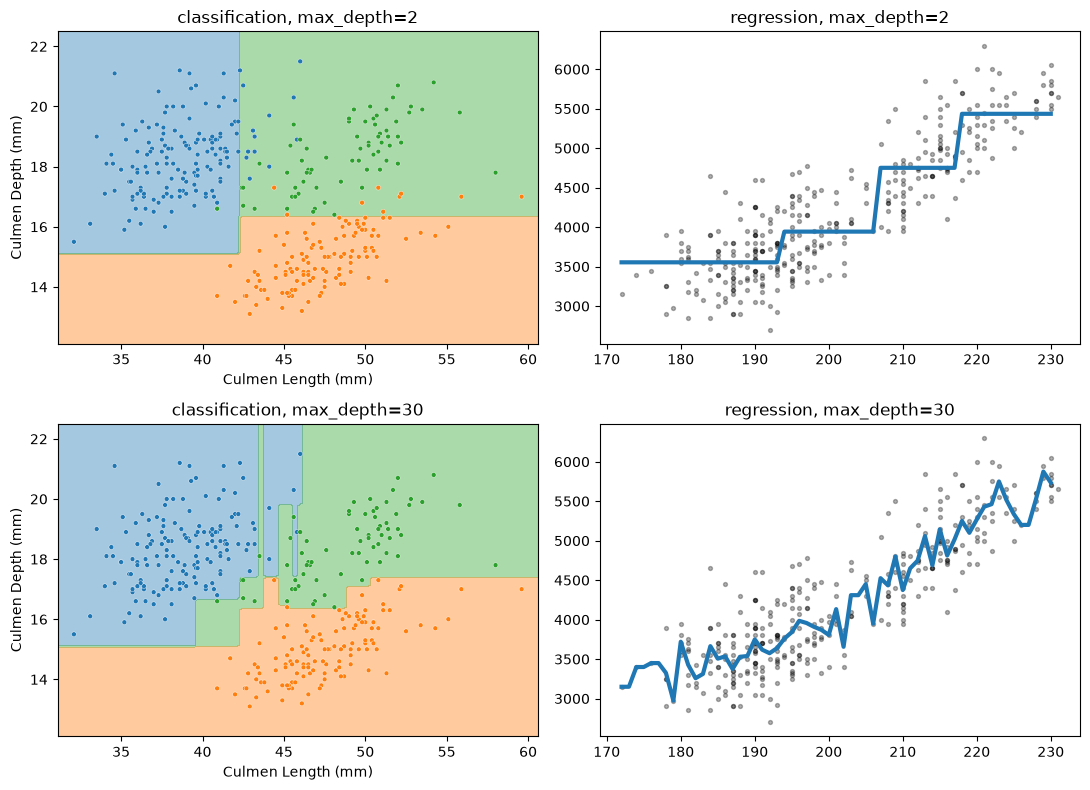

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for row, depth in enumerate([2, 30]):
    fit_and_plot_classification(DecisionTreeClassifier(max_depth=depth, random_state=0), axes[row, 0])
    fit_and_plot_regression(DecisionTreeRegressor(max_depth=depth, random_state=0), axes[row, 1])
    axes[row, 0].set_title(f"classification, max_depth={depth}")
    axes[row, 1].set_title(f"regression, max_depth={depth}")
plt.tight_layout()
plt.show()

The deeper trees are more expressive, but they create small regions and jumps that are only right for single, noisy penguins. There is no depth that suits every dataset: `max_depth` must be tuned for each problem, for example with `GridSearchCV`, as Section 2 did for churn.

`max_depth` cuts the tree horizontally at the same level everywhere. Yet some regions of the data may need many splits and others none. The next cell builds such data: two blobs that overlap (hard) and two that are far apart (easy).

In [22]:
from sklearn.datasets import make_blobs

X_1, y_1 = make_blobs(n_samples=300, centers=[[0, 0], [-1, -1]], random_state=0)   # interlaced
X_2, y_2 = make_blobs(n_samples=300, centers=[[3, 6], [7, 0]], random_state=0)     # easy to separate
blobs = pd.DataFrame(np.vstack([X_1, X_2]), columns=["Feature #0", "Feature #1"])
blobs["Class"] = np.concatenate([y_1, y_2])

Next we compare three trees on the blobs: `max_depth=2`, `max_depth=6` and `min_samples_leaf=60` (every leaf must hold at least 60 points). `get_depth()` and `get_n_leaves()` describe the size of each fitted tree.

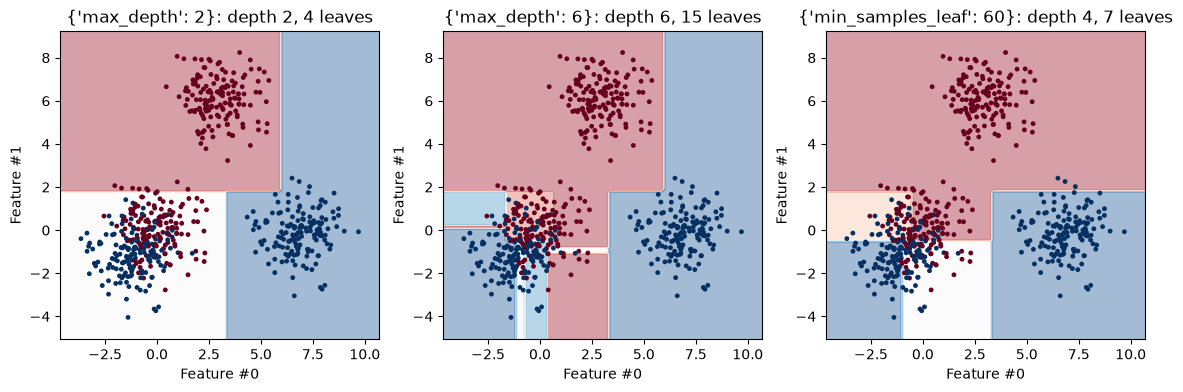

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, params in zip(axes, [{"max_depth": 2}, {"max_depth": 6}, {"min_samples_leaf": 60}]):
    m = DecisionTreeClassifier(random_state=0, **params).fit(blobs[["Feature #0", "Feature #1"]], blobs["Class"])
    DecisionBoundaryDisplay.from_estimator(m, blobs[["Feature #0", "Feature #1"]], cmap="RdBu", alpha=0.4, ax=ax)
    ax.scatter(blobs["Feature #0"], blobs["Feature #1"], c=blobs["Class"], cmap="RdBu", s=6)
    ax.set_title(f"{params}: depth {m.get_depth()}, {m.get_n_leaves()} leaves")
plt.show()

With depth 2 the easy blobs are already separated, but the overlapping blobs need more splits. Depth 6 adds them only on the hard side, because a pure node is never split. `min_samples_leaf` (like `min_samples_split`, `max_leaf_nodes` and `min_impurity_decrease`) puts the limit on the leaves instead of the levels, so the tree may grow deeper where the data need it and stop early where they do not.

### 2b · The whole pruning path on the churn data (depth: self-study or if time allows)

*Adapted from [Post pruning decision trees with cost complexity pruning](extras/04-cost-complexity-pruning.ipynb) (scikit-learn developers, BSD-3-Clause).*

Minimal cost-complexity pruning repeatedly removes the "weakest link": the branch whose removal costs the least impurity per leaf saved. Each removal happens at an **effective alpha**. `cost_complexity_pruning_path` returns these alphas and the total impurity of the leaves at each step. Next we plot that impurity against alpha (the last alpha, which leaves only the root, is dropped).

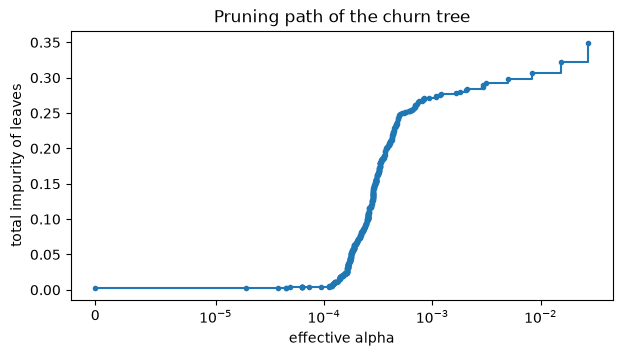

In [24]:
ccp_alphas, impurities = path.ccp_alphas[:-1], path.impurities[:-1]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ccp_alphas, impurities, marker="o", markersize=3, drawstyle="steps-post")
ax.set_xscale("symlog", linthresh=1e-5)
ax.set_xlabel("effective alpha")
ax.set_ylabel("total impurity of leaves")
ax.set_title("Pruning path of the churn tree")
plt.show()

Next we fit one tree for every tenth alpha on the path and record its number of nodes, its depth, and its accuracy on the training and the test customers. (For a real choice of alpha we use cross-validation, as in the cell above; the test set here only illustrates the pattern.)

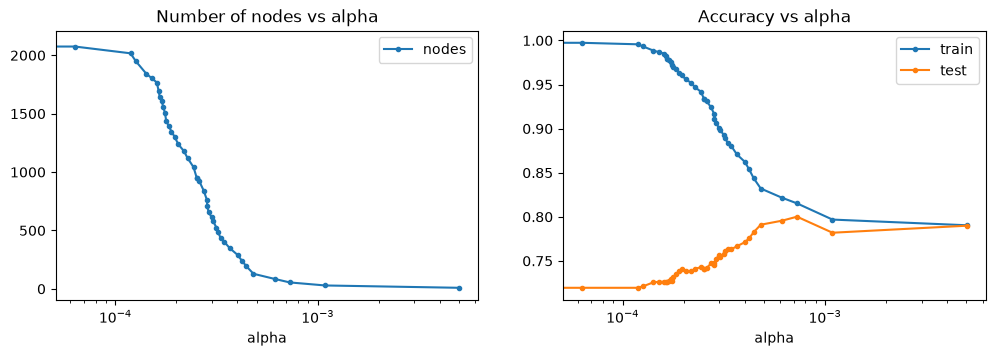

alpha     0.0007
nodes    55.0000
depth     9.0000
train     0.8152
test      0.8001
Name: 39, dtype: float64

In [25]:
rows = []
for a in ccp_alphas[::10]:
    m = DecisionTreeClassifier(random_state=0, ccp_alpha=a).fit(X_tr, y_tr)
    rows.append({"alpha": a, "nodes": m.tree_.node_count, "depth": m.get_depth(),
                 "train": m.score(X_tr, y_tr), "test": m.score(X_te, y_te)})
prune = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
prune.plot(x="alpha", y=["nodes"], logx=True, ax=axes[0], marker="o", ms=3, title="Number of nodes vs alpha")
prune.plot(x="alpha", y=["train", "test"], logx=True, ax=axes[1], marker="o", ms=3, title="Accuracy vs alpha")
plt.show()
prune.loc[prune["test"].idxmax()].round(4)

As alpha grows, the tree shrinks from more than a thousand nodes to a handful, the training accuracy falls towards the share of stayers, and the test accuracy first rises and then falls again: the same under- and overfitting trade-off as with `max_depth`, reached from the other end.

> 📖 **Read more:** [extras/02-trees-hyperparameters.ipynb](extras/02-trees-hyperparameters.ipynb) (INRIA MOOC) and [extras/04-cost-complexity-pruning.ipynb](extras/04-cost-complexity-pruning.ipynb) (scikit-learn gallery): the originals, on the penguins and the breast-cancer data.

## 3 · Bagging and random forests

If one deep tree is unstable, train many and average them. Asking several doctors for an opinion works the same way: each may be wrong in their own direction, and the errors partly cancel out. An **ensemble** combines many models into one prediction.

**Bagging** (bootstrap aggregating; Breiman, 1996) trains each tree on a **bootstrap sample**: n rows drawn *with replacement* from the n training rows, so some rows appear several times and others not at all. The ensemble predicts the average of the trees' probabilities.

Averaging only helps if the trees make *different* errors. Trees grown on bootstrap samples of the same data are still similar, because the same strong feature tends to win the top split every time. A **random forest** (Breiman, 2001) adds a second source of randomness: at each split, a tree may only choose among a random subset of the features (`max_features`, often √p of the p features). The trees become more diverse, and their average more accurate.

Each tree never sees some of the training rows. A random forest can score every row with the trees that did not see it: the **out-of-bag (OOB) score** (`oob_score=True`).

Next we draw one bootstrap sample of ten row numbers. `rng.integers(0, 10, 10)` draws ten integers from 0 to 9 with replacement.

In [26]:
rng = np.random.default_rng(0)
sample = np.sort(rng.integers(0, 10, 10))
print("bootstrap sample:", sample)
print("rows never drawn:", sorted(set(range(10)) - set(sample)))

bootstrap sample: [0 0 0 1 2 3 5 6 8 8]
rows never drawn: [4, 7, 9]


**Predict before running.** We compare one deep tree, 200 bagged deep trees and a random forest of 200 trees on the test customers, by ROC AUC. Which order do you expect? `BaggingClassifier(DecisionTreeClassifier(), n_estimators=200)` is plain bagging; `RandomForestClassifier` adds the random feature subsets. `n_jobs=-1` uses all CPU cores.

In [27]:
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.metrics import roc_auc_score


def auc(model):
    """Test ROC AUC of a fitted binary classifier."""
    return round(roc_auc_score(y_te, model.predict_proba(X_te)[:, 1]), 3)


deep = DecisionTreeClassifier(random_state=0).fit(X_tr, y_tr)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, oob_score=True,
                            random_state=0, n_jobs=-1).fit(X_tr, y_tr)
print("deep tree", auc(deep), "| bagging", auc(bag), "| random forest", auc(rf))

deep tree 0.658 | bagging 0.814 | random forest 0.844


Next we compare the free OOB estimate with the accuracy on the test customers, and watch the OOB score as the forest grows. More trees never make a forest overfit; the average just settles down.

In [28]:
print("OOB accuracy", round(rf.oob_score_, 3), "| test accuracy", round(rf.score(X_te, y_te), 3))
for n in [25, 100, 300]:
    m = RandomForestClassifier(n_estimators=n, min_samples_leaf=5, oob_score=True,
                               random_state=0, n_jobs=-1).fit(X_tr, y_tr)
    print(n, "trees: OOB accuracy", round(m.oob_score_, 3))

OOB accuracy 0.802 | test accuracy 0.798
25 trees: OOB accuracy 0.793


100 trees: OOB accuracy 0.802


300 trees: OOB accuracy 0.804


The OOB accuracy (0.802) is close to the test accuracy (0.798), without setting any data aside. Growing the forest from 25 to 100 trees raises the OOB accuracy from 0.793 to 0.802; 300 trees add little (0.804). Random forests are accurate with almost no tuning, which makes them the baseline any tabular model should beat.

### 3a · Bagging step by step (depth: self-study or if time allows)

*Adapted from [Bagging](extras/05-ensemble-bagging.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

A small synthetic regression problem makes bagging visible. The target is a noisy cubic function of one feature; 30 training points, and a grid of 300 points on which we draw predictions. ("Test" here only means "not used for training".)

In [29]:
def generate_data(n_samples=30):
    """Noisy cubic curve: returns training features, a plotting grid and the training target."""
    rng = np.random.default_rng(1)
    x = rng.uniform(-3, 3, size=n_samples)
    y = x ** 3 - 0.5 * (x + 1) ** 2 + 4.0 * rng.normal(size=n_samples)
    y /= y.std()
    return (pd.DataFrame(x, columns=["Feature"]), pd.DataFrame(np.linspace(3, -3, 300), columns=["Feature"]),
            pd.Series(y, name="Target"))


data_train_s, data_grid, target_train_s = generate_data()

A bootstrap sample draws n row positions with replacement. `rng.choice(n, size=n, replace=True)` does this; `.iloc` selects the rows by position. Next we draw three bootstrap samples and plot each over the original points: rows drawn several times show as darker circles, and some original points are missing.

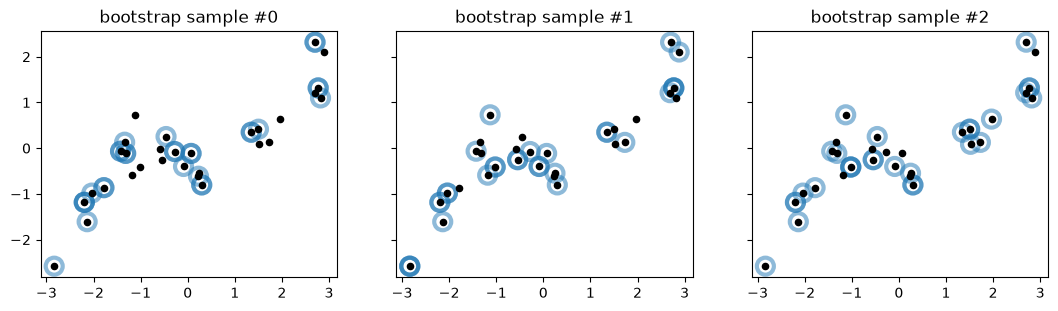

In [30]:
def bootstrap_sample(data, target, seed=0):
    idx = np.random.default_rng(seed).choice(len(target), size=len(target), replace=True)
    return data.iloc[idx], target.iloc[idx]


fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for seed, ax in enumerate(axes):
    d_b, t_b = bootstrap_sample(data_train_s, target_train_s, seed=seed)
    ax.scatter(d_b["Feature"], t_b, facecolors="none", edgecolors="tab:blue", s=150, linewidth=3, alpha=0.5)
    ax.scatter(data_train_s["Feature"], target_train_s, color="black", s=20)
    ax.set_title(f"bootstrap sample #{seed}")
plt.show()

How many *distinct* original rows does a bootstrap sample contain? Next we check with a large dataset of 100,000 rows; `np.unique` counts the distinct values.

In [31]:
big_data, _, big_target = generate_data(n_samples=100_000)
d_b, _ = bootstrap_sample(big_data, big_target)
print(f"share of original rows in the bootstrap sample: {np.unique(d_b).size / len(d_b):.3f}")

share of original rows in the bootstrap sample: 0.632


Next we fit one depth-3 tree on each of the three bootstrap samples, draw their predictions (dashed) and their average (solid). The average is the bagging prediction.

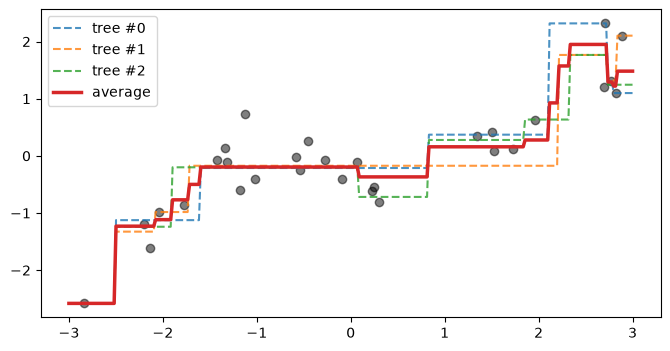

In [32]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(data_train_s["Feature"], target_train_s, color="black", alpha=0.5)
preds = []
for seed in range(3):
    d_b, t_b = bootstrap_sample(data_train_s, target_train_s, seed=seed)
    preds.append(DecisionTreeRegressor(max_depth=3, random_state=0).fit(d_b, t_b).predict(data_grid))
    ax.plot(data_grid["Feature"], preds[-1], "--", alpha=0.8, label=f"tree #{seed}")
ax.plot(data_grid["Feature"], np.mean(preds, axis=0), color="tab:red", lw=2.5, label="average")
ax.legend()
plt.show()

The averaged curve is smoother and more stable than any single tree. scikit-learn wraps this procedure in the **meta-estimator** `BaggingRegressor` (or `BaggingClassifier`): it clones a base model `n_estimators` times and fits each clone on its own bootstrap sample; the fitted clones are in `estimators_`. Next we bag 100 trees and draw every tree faintly behind the ensemble.

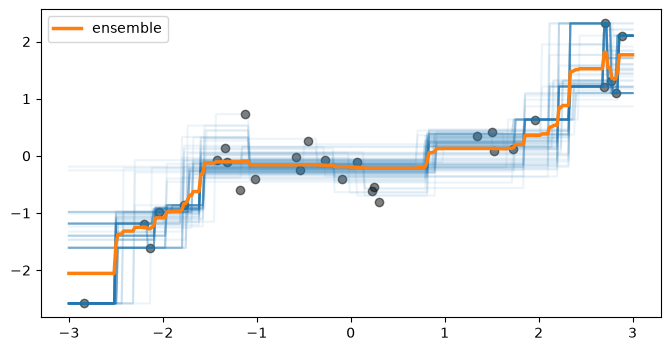

In [33]:
from sklearn.ensemble import BaggingRegressor

bagged_trees = BaggingRegressor(DecisionTreeRegressor(max_depth=3), n_estimators=100, random_state=0)
bagged_trees.fit(data_train_s, target_train_s)
fig, ax = plt.subplots(figsize=(8, 4))
for m in bagged_trees.estimators_:
    ax.plot(data_grid["Feature"], m.predict(data_grid.to_numpy()), color="tab:blue", alpha=0.08)
ax.scatter(data_train_s["Feature"], target_train_s, color="black", alpha=0.5)
ax.plot(data_grid["Feature"], bagged_trees.predict(data_grid), color="tab:orange", lw=2.5, label="ensemble")
ax.legend()
plt.show()

The spread of the faint lines shows where the individual trees disagree, a rough picture of the uncertainty of the prediction. Bagging is not limited to trees: any model can be the base model. Next we bag a polynomial regression pipeline (`MinMaxScaler`, degree-4 `PolynomialFeatures`, an almost unregularised `Ridge`), which matches how the data were generated.

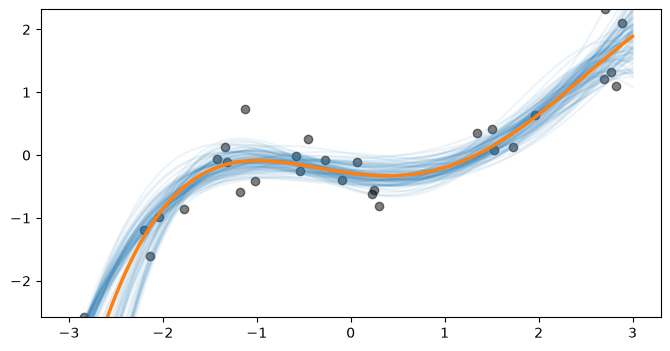

In [34]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures

poly = make_pipeline(MinMaxScaler(), PolynomialFeatures(degree=4, include_bias=False), Ridge(alpha=1e-10))
bagging_poly = BaggingRegressor(poly, n_estimators=100, random_state=0).fit(data_train_s, target_train_s)
fig, ax = plt.subplots(figsize=(8, 4))
for m in bagging_poly.estimators_:
    ax.plot(data_grid["Feature"], m.predict(data_grid.to_numpy()), color="tab:blue", alpha=0.08)
ax.scatter(data_train_s["Feature"], target_train_s, color="black", alpha=0.5)
ax.plot(data_grid["Feature"], bagging_poly.predict(data_grid), color="tab:orange", lw=2.5)
ax.set_ylim(target_train_s.min(), target_train_s.max())
plt.show()

The bagged polynomial looks better than the bagged trees here, because its base model fits the true shape of the data. The bootstrap itself is a general statistical tool (Session 7), not only a way to build ensembles.

### 3b · Why decorrelation matters: `max_features` (depth: self-study or if time allows)

*The table and the advice on `max_features` are adapted from [Random forests](extras/06-ensemble-random-forest.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

Averaging B predictions that each have variance σ² gives variance σ²/B if the predictions are independent. Trees fitted to bootstrap samples of the same data are positively correlated, with correlation ρ, and then the variance of their average is

ρ · σ² + (1 − ρ) · σ² / B.

More trees shrink only the second term; the first term stays. To lower it, the trees must be less alike. A random forest randomises along **both axes of the data table**: rows (a bootstrap sample per tree) and columns (a random subset of features at each split node). The amount of column randomness is set by `max_features`:

- `max_features=0.5`: half of the features are candidates at each split;
- `max_features=1.0`: all features, which turns the random forest into bagged trees.

| Ensemble class | Base model | Default `max_features` | Feature subsampling |
|---|---|---|---|
| `BaggingClassifier` | chosen by the user | all features (no subsampling) | once per model |
| `RandomForestClassifier` | `DecisionTreeClassifier` | `sqrt(n_features)` | at every split node |
| `BaggingRegressor` | chosen by the user | all features (no subsampling) | once per model |
| `RandomForestRegressor` | `DecisionTreeRegressor` | all features (no subsampling) | at every split node |

Too much randomness gives weak, underfitting trees; too little leaves the trees correlated, so averaging helps less. `max_features` is therefore one of the few random forest settings worth tuning. Next we score forests with four values on the churn training data (3-fold CV to keep it quick). **Predict:** which value wins?

In [35]:
for mf in [1, "sqrt", 0.5, 1.0]:
    rf_mf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, max_features=mf, random_state=0, n_jobs=-1)
    print(f"max_features={mf!s:<5} CV ROC AUC {cross_val_score(rf_mf, X_tr, y_tr, cv=3, scoring='roc_auc').mean():.3f}")

max_features=1     CV ROC AUC 0.843


max_features=sqrt  CV ROC AUC 0.843


max_features=0.5   CV ROC AUC 0.835


max_features=1.0   CV ROC AUC 0.831


One random candidate feature per split and √p candidates give the same cross-validated ROC AUC (0.843); half of the features gives 0.835, and all features (bagged trees) 0.831. On the churn data more randomness helps: with all features the trees are too much alike.

> 📖 **Read more:** [extras/05-ensemble-bagging.ipynb](extras/05-ensemble-bagging.ipynb) and [extras/06-ensemble-random-forest.ipynb](extras/06-ensemble-random-forest.ipynb) (INRIA MOOC): the originals, including a tree versus bagging versus random forest comparison on the Adult census data.

## 4 · Gradient boosting

**Boosting** builds the ensemble one tree after another. Think of a golfer: the first shot gets close to the hole, and every following putt corrects the remaining distance. For a numeric target:

1. Start with a constant prediction, the mean of y.
2. Compute the **residuals**: target minus current prediction, what the model still gets wrong.
3. Fit a *small* tree (depth 2 to 6) to the residuals.
4. Add that tree's prediction, multiplied by a **learning rate** η between 0 and 1.
5. Repeat many times.

For squared error, the residuals are the negative gradient of the loss, hence the name **gradient boosting** (Friedman, 2001). For classification the same loop runs on the log-odds scale, and each tree fits "observed class minus predicted probability".

**Worked example** (one row): y = 10, the start is 6, so the residual is 4. Tree 1 predicts 4; with η = 0.5 the prediction becomes 6 + 0.5 · 4 = 8. The new residual is 2; tree 2 predicts 2, and the prediction becomes 8 + 0.5 · 2 = 9. The prediction approaches the target in shrinking steps.

Bagging averages deep trees to reduce *variance*. Boosting adds small trees to reduce *bias*. Because every tree fits the remaining errors, boosting eventually fits noise: the number of trees has to be controlled (block 2: early stopping).

Next we make a toy regression problem: 200 points on a sine curve plus noise with standard deviation 0.2 (variance 0.04).

In [36]:
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(0, 6, 200)).reshape(-1, 1)
target = np.sin(x[:, 0]) + rng.normal(0, 0.2, 200)

Now boosting by hand: 50 rounds of depth-2 `DecisionTreeRegressor`s, each fitted to the current residuals, with learning rate 0.3. We keep the prediction after 1, 5, 20 and 50 trees for the plot and print the training error (mean squared error).

In [37]:
from sklearn.tree import DecisionTreeRegressor

pred, lr, stages = np.full(200, target.mean()), 0.3, {}
for step in range(1, 51):
    residual = target - pred                       # what the model still gets wrong
    tree = DecisionTreeRegressor(max_depth=2).fit(x, residual)
    pred = pred + lr * tree.predict(x)
    if step in (1, 5, 20, 50):
        stages[step] = pred.copy()
        print(step, "trees: training MSE", round(np.mean((target - pred) ** 2), 3))

1 trees: training MSE 0.294
5 trees: training MSE 0.067
20 trees: training MSE 0.031
50 trees: training MSE 0.02


The plot shows the fit growing from a step function into a curve.

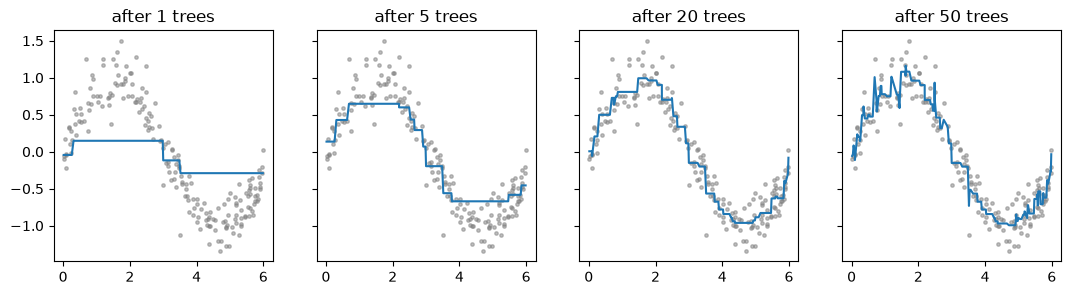

In [38]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for ax, (step, p) in zip(axes, stages.items()):
    ax.scatter(x, target, s=6, color="grey", alpha=0.5)
    ax.plot(x, p, color="C0")
    ax.set_title(f"after {step} trees")
plt.show()

The training error drops below the noise variance of 0.04: from that point on the model is fitting noise. scikit-learn does the same loop for classification. `GradientBoostingClassifier` is the classic implementation; `HistGradientBoostingClassifier` first sorts each feature into at most 255 bins, which makes it much faster on large data (the same trick as LightGBM in block 2). Next we fit both on the churn data.

In [39]:
from sklearn.ensemble import GradientBoostingClassifier, HistGradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=0).fit(X_tr, y_tr)
hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0).fit(X_tr, y_tr)
print("GradientBoosting", auc(gb), "| HistGradientBoosting", auc(hgb))

GradientBoosting 0.846 | HistGradientBoosting 0.844


> **Note.** Boosting wants **small** trees and a moderate learning rate; deep trees with a high learning rate overfit within a few rounds. Random forests do the opposite and use deep trees.

### 4a · Residuals, drawn (depth: self-study or if time allows)

*Adapted from [Gradient-boosting decision tree](extras/07-ensemble-gradient-boosting.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

AdaBoost, an older boosting method, re-weights the rows that were predicted badly. Gradient boosting instead fits each new tree to the **residuals** of the current model. To see this, we use 50 points on a noisy cubic curve and a deliberately shallow first tree (depth 3).

In [40]:
rng_gb = np.random.default_rng(0)
x_gb = rng_gb.uniform(-1.4, 1.4, size=50)
gb_train = pd.DataFrame({"Feature": x_gb})
gb_target = pd.Series(x_gb ** 3 - 0.5 * x_gb ** 2 + 0.3 * rng_gb.normal(size=50))
gb_grid = pd.DataFrame({"Feature": np.linspace(1.4, -1.4, 300)})

tree1 = DecisionTreeRegressor(max_depth=3, random_state=0).fit(gb_train, gb_target)
fitted1 = tree1.predict(gb_train)

A helper draws the data, a model's prediction curve (dashed) and each residual as a red vertical line from the point to the prediction.

In [41]:
def plot_with_residuals(y_true, y_fitted, y_grid, title, ax):
    ax.scatter(gb_train["Feature"], y_true, color="black", alpha=0.5, s=12)
    ax.plot(gb_grid["Feature"], y_grid, "--")
    for xv, yt, yp in zip(gb_train["Feature"], y_true, y_fitted):
        ax.plot([xv, xv], [yt, yp], color="red", lw=1)
    ax.set_title(title)

Next we compute the residuals of the first tree and fit a second tree (depth 5) to them, not to the target. The left panel shows the first tree and its errors; the right panel the second tree trying to predict those errors.

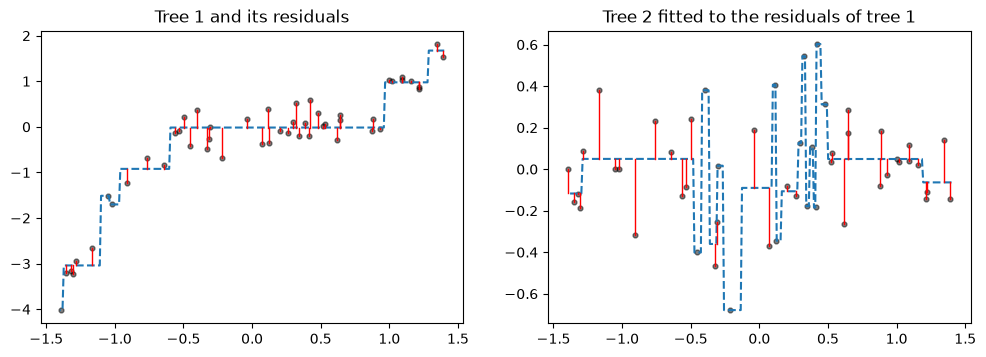

In [42]:
residuals = gb_target - fitted1
tree2 = DecisionTreeRegressor(max_depth=5, random_state=0).fit(gb_train, residuals)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_with_residuals(gb_target, fitted1, tree1.predict(gb_grid), "Tree 1 and its residuals", axes[0])
plot_with_residuals(residuals, tree2.predict(gb_train), tree2.predict(gb_grid),
                    "Tree 2 fitted to the residuals of tree 1", axes[1])
plt.show()

Take one training point, the seventh from the end, as in the original notebook. Next we print its target, the first tree's prediction, the second tree's prediction of the residual, and the sum of both trees.

In [43]:
i = len(gb_train) - 7
s = gb_train.iloc[[i]]
p1, p2 = tree1.predict(s)[0], tree2.predict(s)[0]
print(f"target {gb_target.iloc[i]:.3f} | tree 1 {p1:.3f} (error {gb_target.iloc[i] - p1:.3f})")
print(f"tree 2 predicts the residual {p2:.3f} | tree 1 + tree 2 = {p1 + p2:.3f} "
      f"(error {gb_target.iloc[i] - p1 - p2:.3f})")

target -0.417 | tree 1 -0.016 (error -0.401)
tree 2 predicts the residual -0.401 | tree 1 + tree 2 = -0.417 (error 0.000)


For this point two trees are enough. For most points they are not: the third tree corrects the remaining errors of the first two, and so on. Real implementations also multiply each tree by the learning rate, so no single tree is allowed to correct the whole error.

### 4b · Why histogram boosting is fast (depth: self-study or if time allows)

*Adapted from [Speeding-up gradient-boosting](extras/08-hist-gradient-boosting.ipynb) (INRIA scikit-learn MOOC, CC BY 4.0).*

Unlike a forest, boosting cannot fit its trees in parallel: tree N needs the residuals of trees 1 to N − 1. The expensive step is the split search, which tries every threshold of every feature. **Binning** each feature into at most 256 intervals first reduces the number of candidate thresholds, and adding more trees makes up for the coarser splits. `KBinsDiscretizer(n_bins=256, encode="ordinal", strategy="quantile")` does the binning by quantiles; next we count the distinct values per numeric churn feature before and after.

In [44]:
import warnings

from sklearn.preprocessing import KBinsDiscretizer

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore")              # warns when a feature has fewer distinct values than bins
    binned = KBinsDiscretizer(n_bins=256, encode="ordinal", strategy="quantile").fit_transform(X_tr[num_cols])
print("distinct values before:", X_tr[num_cols].nunique().to_dict())
print("distinct bins after:   ", dict(zip(num_cols, [len(np.unique(col)) for col in binned.T])))

distinct values before: {'tenure': 73, 'MonthlyCharges': 1463, 'TotalCharges': 4949}
distinct bins after:    {'tenure': 72, 'MonthlyCharges': 246, 'TotalCharges': 256}


`HistGradientBoostingClassifier` builds the histograms internally. Next we compare the fit time and the cross-validated ROC AUC of the classic and the histogram implementation on the churn training data, with 200 trees of depth 3 each.

In [45]:
for name, m in [("GradientBoosting", GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=0)),
                ("HistGradientBoosting", HistGradientBoostingClassifier(max_iter=200, max_depth=3, random_state=0))]:
    res = cross_validate(m, X_tr, y_tr, cv=3, scoring="roc_auc")
    print(f"{name:<21} ROC AUC {res['test_score'].mean():.3f}   fit {res['fit_time'].mean():.2f} s")

GradientBoosting      ROC AUC 0.842   fit 0.51 s


HistGradientBoosting  ROC AUC 0.842   fit 0.11 s


Binning changes little for `tenure` (73 distinct values, 72 bins) but reduces `TotalCharges` from 4,949 distinct values to 256 bins. On 5,282 training customers both implementations reach the same ROC AUC (0.842) and the histogram version fits about four to five times faster (0.11 against 0.51 seconds per fit in this run; times depend on the machine). The INRIA notebook notes that the histogram version becomes much more efficient from about 10,000 rows on. LightGBM (block 2) is built on the same idea.

> 📖 **Read more:** [extras/07-ensemble-gradient-boosting.ipynb](extras/07-ensemble-gradient-boosting.ipynb) and [extras/08-hist-gradient-boosting.ipynb](extras/08-hist-gradient-boosting.ipynb) (INRIA MOOC): the originals, with a gradient boosting versus random forest comparison on the California housing data. [extras/09-islp-tree-based-methods-lab.ipynb](extras/09-islp-tree-based-methods-lab.ipynb) (ISLP labs, BSD-2-Clause): the textbook's lab for the whole chapter, from classification and regression trees to bagging, random forests, boosting and BART (needs the `ISLP` package).

## Worked example · Tree, forest or boosting for churn?

The practice task of this block: fit a decision tree on the churn data, then compare it with a random forest and a gradient boosting model **on the same folds**. Same folds means every model is scored on exactly the same customers, so the differences come from the models and not from luck of the split. We add the logistic regression of Session 8 as the current model.

Next we fix one `StratifiedKFold` object and pass it to `cross_validate` for every model. The tree uses the limits found by the grid search in Section 2 (`search.best_params_`).

In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

folds = StratifiedKFold(5, shuffle=True, random_state=0)
models = {
    "tree (tuned)": DecisionTreeClassifier(**search.best_params_, random_state=0),
    "random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=0, n_jobs=-1),
    "gradient boosting": HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=3, random_state=0),
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
}
scores = {name: cross_validate(m, X_tr, y_tr, cv=folds, scoring="roc_auc") for name, m in models.items()}
pd.DataFrame({name: {"ROC AUC": s["test_score"].mean(), "sd over folds": s["test_score"].std(),
                     "fit seconds": s["fit_time"].mean()} for name, s in scores.items()}).T.round(3)

,ROC AUC,sd over folds,fit seconds
tree (tuned),0.826,0.012,0.006
random forest,0.843,0.015,0.138
gradient boosting,0.846,0.014,0.142
logistic regression,0.845,0.014,0.005


Because the folds are shared, we can look at the **paired** difference per fold: forest minus tree, and boosting minus forest.

In [47]:
fold_auc = pd.DataFrame({name: s["test_score"] for name, s in scores.items()})
print("forest - tree:   ", (fold_auc["random forest"] - fold_auc["tree (tuned)"]).round(3).to_list())
print("boosting - forest:", (fold_auc["gradient boosting"] - fold_auc["random forest"]).round(3).to_list())

forest - tree:    [0.014, 0.013, 0.024, 0.019, 0.018]
boosting - forest: [0.01, 0.006, -0.006, 0.007, -0.004]


The random forest beats the tuned single tree in all five folds, by 0.013 to 0.024 ROC AUC: averaging many trees clearly pays. Boosting against the forest is a different story: the differences run from −0.006 to +0.010, and the mean ROC AUC (0.846 against 0.843) differs by less than the spread across folds (about 0.014). The logistic regression of Session 8 reaches 0.845 and fits in a fraction of the time. On the churn data, the effects are few, strong and mostly monotone, so a more flexible model has little to add.

That is the first answer to the guiding question of the session, "Can a more flexible model do better, and what does it cost?": on churn, ensembles beat a single tree, but not the current linear model. Block 2 asks the same question for the Berlin prices, where the answer differs.

## Check your understanding

1. A node has 30 churners and 70 stayers. What is its Gini impurity?
2. A split gives a left child with 20 rows (G = 0.1) and a right child with 80 rows (G = 0.4). What is the weighted impurity?
3. The unlimited tree has a training accuracy close to 1 and a much lower cross-validated accuracy. Which two hyperparameters would you tune first, and on which data?
4. Why does a random forest choose among a random subset of features at each split?
5. Bagging reduces variance, boosting mainly reduces bias. Explain this with the depth of the trees each method uses.

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Answer *Paper*, *Predict* and *Class* tasks in the cell below the task before running any code. The code exercises use the Berlin Airbnb listings; run the setup cell first.

In [48]:
from sklearn.model_selection import GroupKFold

# Short-stay listings with a price, as in the price model of Sessions 6-9
listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
bnb = listings[(listings["minimum_nights"] < 28) & listings["price"].between(10, 1000)].reset_index(drop=True)
bnb["dist_km"] = np.hypot((bnb["latitude"] - 52.5219) * 111.2,      # km to Alexanderplatz
                          (bnb["longitude"] - 13.4132) * 68.0)
num = ["accommodates", "bedrooms", "beds", "bathrooms", "dist_km", "minimum_nights",
       "availability_365", "number_of_reviews", "review_scores_rating"]
y_bnb, price, hosts = np.log(bnb["price"]), bnb["price"], bnb["host_id"]
host_folds = list(GroupKFold(5).split(bnb, groups=hosts))     # the same host-grouped folds for every model
print(len(bnb), "listings,", hosts.nunique(), "hosts")

6675 listings, 3737 hosts


### 1.1 · Gini by hand

*Paper · 10 min*

> A node with 6 churners and 4 stayers. What is its Gini impurity?
>
> Ten listings, and whether each was busy last year (1 = busy):
>
> | Listing | Guests | Room | Busy |
> |---|---|---|---|
> | 1 | 1 | private | 0 |
> | 2 | 2 | private | 0 |
> | 3 | 2 | private | 1 |
> | 4 | 2 | entire | 1 |
> | 5 | 3 | entire | 1 |
> | 6 | 4 | entire | 1 |
> | 7 | 4 | private | 0 |
> | 8 | 5 | entire | 1 |
> | 9 | 6 | entire | 0 |
> | 10 | 8 | entire | 0 |
>
> Find the best first split: compute the weighted Gini impurity of the split on *Room* and of every threshold on *Guests*. Which split does a tree choose?

*Source:* [scikit-learn: Decision trees, mathematical formulation](https://scikit-learn.org/stable/modules/tree.html); the table of ten listings is an original exercise for this course.

*Your answer:*

### 1.2 · Twenty questions

*Class · 10 min*

> One student thinks of an object; the class asks yes/no questions. Why is "Is it alive?" a good first question?

*Source:* [Twenty questions, Wikipedia](https://en.wikipedia.org/wiki/Twenty_questions)

*Your answer:*

### 1.3 · XOR

*Paper · 10 min*

> Four points of XOR: (0, 0) and (1, 1) belong to class 0, (0, 1) and (1, 0) to class 1. Which first split improves the impurity? Can a tree of depth 2 classify all four points?

*Source:* [Decision tree learning, Wikipedia](https://en.wikipedia.org/wiki/Decision_tree_learning)

*Your answer:*

### 1.4 · Can a tree extrapolate?

*Predict · 10 min*

> A regression tree is trained on Berlin listings for 1 to 6 guests. What does it predict for 16 guests? Write down your prediction and sketch the predicted price against the number of guests.
>
> Then check it: fit a `DecisionTreeRegressor(max_depth=4)` on the `bnb` rows with `accommodates <= 6`, using `accommodates` as the only feature and `price` as the target, and predict for 1 to 16 guests. Compare with a linear regression on the same rows.

*Source:* original exercise for this course; background: [scikit-learn example: Decision tree regression](https://scikit-learn.org/stable/auto_examples/tree/plot_tree_regression.html)

*Your answer:*

### 1.5 · Wisdom of the crowd

*Class · 10 min*

> The lecturer shows one Berlin listing on screen. Everyone writes down its nightly price on a slip of paper. Compare the class average with the individual guesses: how many of you were closer to the true price than the average?

*Source:* [Galton (1907), "Vox populi", *Nature* 75](https://doi.org/10.1038/075450a0)

*Your answer:*

### 1.6 · Majority vote

*Paper · 10 min*

> Five independent models, each 60 % accurate. How accurate is their majority vote? And if all five models are identical?

*Source:* [Condorcet's jury theorem, Wikipedia](https://en.wikipedia.org/wiki/Condorcet%27s_jury_theorem)

*Your answer:*

### 1.7 · Boosting by hand

*Paper · 15 min*

> Five listings:
>
> | Guests | 1 | 2 | 3 | 4 | 6 |
> |---|---|---|---|---|---|
> | Price (€) | 40 | 50 | 70 | 90 | 150 |
>
> Round 1 predicts the mean price. Compute the residuals. Round 2 fits the residuals with one split on *Guests* (try every threshold; choose the one with the smallest sum of squared residuals). Add the two predictions (learning rate 1) and compute the new residuals. What would change with a learning rate of 0.5?

*Source:* [Friedman (2001), "Greedy function approximation: a gradient boosting machine", *Annals of Statistics*](https://doi.org/10.1214/aos/1013203451)

*Your answer:*

### 1.8 · Free validation

*Paper · 5 min*

> A random forest of 200 trees is trained on the 5,282 churn training customers with `oob_score=True`.
>
> 1. About how many of the 200 trees can vote on the out-of-bag prediction of one customer? Use the share of rows in a bootstrap sample from Section 3a.
> 2. With only 10 trees, scikit-learn warns that some customers have no out-of-bag prediction. About how many customers is that, and why?

*Source:* [Breiman (2001), "Random forests", *Machine Learning* 45](https://doi.org/10.1023/A:1010933404324)

*Your answer:*

### 1.9 · A price tree and a forest

*Pairs · 20 min*

> Predict the log price `y_bnb` of the Berlin listings from the numeric columns `num` (setup cell).
>
> 1. Fit `DecisionTreeRegressor(max_depth=d, min_samples_leaf=5)` for `d` from 1 to 15 and compute the training and the cross-validated R² on the host-grouped `host_folds` (`cross_validate(..., cv=host_folds, return_train_score=True)`). Plot both against the depth. Which depth do you choose?
> 2. Score a `RandomForestRegressor(n_estimators=200, min_samples_leaf=3, n_jobs=-1)` on the same folds. How much better is it than the best single tree?
>
> *Stretch:* fit the chosen tree on 10 bootstrap samples of the listings and print the first two splits each time (`export_text(..., max_depth=1)`). What do you conclude about the stability of single trees?

*Source:* original exercise for this course; background: [scikit-learn: Decision trees](https://scikit-learn.org/stable/modules/tree.html) and [random forests](https://scikit-learn.org/stable/modules/ensemble.html#random-forests)

## Debrief (15 min)

- **Gini by hand (1.1).** Compare the weighted impurities of the candidate splits on the board. Look for the classic mistake: forgetting to weight each child by its share of the rows, which makes a tiny pure child look like a perfect split. Ask who chose *Room* because it "looks more meaningful".
- **XOR and twenty questions (1.2, 1.3).** Both show what greedy search optimises: a good question halves the uncertainty now, and greedy search can miss a split that only pays off one level further down.
- **Extrapolation and the crowd (1.4 to 1.6).** Collect the sketches for 16 guests before showing the code result. Link the class average and the majority vote back to bagging: averaging helps only when the errors are not the same.
- **Code task (1.9).** Compare the chosen depths across pairs and check that every pair used `host_folds`; a random split puts listings of the same host on both sides and flatters the score.

**Bridge to block 2.** Random forests and boosting beat the single tree. Block 2 uses the three libraries that make boosting fast and practical (XGBoost, LightGBM, CatBoost), tunes them, and asks what such a model has learned and whether it is worth replacing the current model.

## Further reading

- James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*, Chapter 8: Tree-based methods (trees, bagging, random forests, boosting). Springer. Free PDF: https://www.statlearning.com/
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow*, 3rd edition, Chapters 6 (decision trees) and 7 (ensemble learning and random forests). O'Reilly.
- scikit-learn developers. *Decision trees* and *Ensembles: gradient boosting, random forests, bagging*. User guide, sections 1.10 and 1.11. https://scikit-learn.org/stable/modules/tree.html and https://scikit-learn.org/stable/modules/ensemble.html
- Breiman, L. (1996). Bagging predictors. *Machine Learning*, 24, 123–140. https://doi.org/10.1007/BF00058655
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32. https://doi.org/10.1023/A:1010933404324
- Friedman, J. H. (2001). Greedy function approximation: a gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232. https://doi.org/10.1214/aos/1013203451
- Amazon Machine Learning University. *MLU-Explain: Decision Trees* and *Random Forest*, interactive articles. https://mlu-explain.github.io/decision-tree/ and https://mlu-explain.github.io/random-forest/
- Data: IBM (2019), *Telco customer churn sample data*, https://github.com/IBM/telco-customer-churn-on-icp4d (Apache-2.0); Inside Airbnb (2026), *Berlin, Germany*, snapshot of 26 June 2026, CC BY 4.0, https://insideairbnb.com/get-the-data/; Horst, A. M., Hill, A. P. & Gorman, K. B. (2020), *palmerpenguins*, CC0-1.0, https://allisonhorst.github.io/palmerpenguins/ (copy from the INRIA MOOC in [../datasets/](../datasets/)).
- Extras of this block (provenance in [extras/README.md](extras/README.md)): [01](extras/01-trees-classification.ipynb), [02](extras/02-trees-hyperparameters.ipynb), [03](extras/03-tree-structure.ipynb), [04](extras/04-cost-complexity-pruning.ipynb), [05](extras/05-ensemble-bagging.ipynb), [06](extras/06-ensemble-random-forest.ipynb), [07](extras/07-ensemble-gradient-boosting.ipynb), [08](extras/08-hist-gradient-boosting.ipynb), [09](extras/09-islp-tree-based-methods-lab.ipynb).

*Course material, licence CC BY 4.0.*